# 02 · The Kalman filter

If the motion and sensor models are **linear** and the noises **Gaussian**, the Bayes filter of
notebook 01 has an exact closed form: a Gaussian belief stays Gaussian, and only its mean and
covariance need updating. That closed form is the Kalman filter (Kalman, 1960).

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path().resolve().parent))

import numpy as np
import matplotlib.pyplot as plt
from bayesian_filters import World, simulate, CompassGpsKF, KalmanFilter, run_filter
from bayesian_filters import position_error, nees, nees_bounds
from bayesian_filters import viz
viz.style()

## 1. Derivation

**Model.**
$$
x_{t+1} = F x_t + B u_t + w_t,\quad w_t\sim\mathcal N(0,Q);
\qquad z_t = H x_t + v_t,\quad v_t\sim\mathcal N(0,R),
$$
with all noises independent. Suppose $\operatorname{bel}(x_t) = \mathcal N(\hat x_t, P_t)$.

**Predict.** $x_{t+1}$ is an affine function of the independent Gaussians $x_t$ and $w_t$, so it
is Gaussian with
$$
\bar x_{t+1} = F\hat x_t + B u_t, \qquad \bar P_{t+1} = F P_t F^\top + Q .
$$

**Update.** Conditionally on the past, $(x_{t+1}, z_{t+1})$ is jointly Gaussian:
$$
\begin{pmatrix} x \\ z\end{pmatrix} \sim \mathcal N\!\left(
\begin{pmatrix} \bar x \\ H\bar x\end{pmatrix},
\begin{pmatrix} \bar P & \bar P H^\top \\ H\bar P & H\bar P H^\top + R\end{pmatrix}\right).
$$
Conditioning a Gaussian on part of its components (Schur complement) gives
$$
\boxed{\;
S = H\bar P H^\top + R,\qquad
K = \bar P H^\top S^{-1},\qquad
\hat x = \bar x + K\,(z - H\bar x),\qquad
P = (I-KH)\,\bar P \;}
$$
* $y = z - H\bar x$ is the **innovation**: what the measurement says that the prediction did
  not. Its covariance is $S$.
* $K$ is the **Kalman gain**: how much of the innovation to believe. In one dimension with
  $H = 1$, $K = \bar P/(\bar P + R)$, a weighted average of prediction and measurement with
  weights inversely proportional to their variances.
* $P = (I-KH)\bar P$ is algebraically equal to the **Joseph form**
  $(I-KH)\bar P(I-KH)^\top + KRK^\top$, which is used in the code because it stays symmetric
  positive semi-definite in floating point arithmetic.

A tiny check, the product of $\mathcal N(0, 4)$ and a measurement $2$ with variance $1$:

In [2]:
kf = KalmanFilter(np.array([0.0]), np.array([[4.0]]))
kf.update(np.array([2.0]), H=np.eye(1), R=np.eye(1))
print(f"posterior mean {kf.x[0]:.2f} (expected 8/5), variance {kf.P[0, 0]:.2f} (expected 4/5), gain {kf.K[0, 0]:.2f}")

posterior mean 1.60 (expected 8/5), variance 0.80 (expected 4/5), gain 0.80


## 2. Making the turtle linear

The turtle's pose model is *not* linear: the heading enters through $\cos$ and $\sin$. We
make the problem linear honestly, with a **compass**. Let $h_t$ be the compass reading taken
after the turn. Then the position obeys
$$
p_{t+1} = p_t + \underbrace{s_t\begin{pmatrix}\cos h_t\\ \sin h_t\end{pmatrix}}_{B u_t:\ \text{known}} + w_t,
$$
which is linear in the state $p$ ($F = B = I$), and the GPS gives $z_t = p_t + v_t$ ($H = I$).

**Process noise.** The true displacement is $(s_t+\varepsilon_s)(\cos\theta_t, \sin\theta_t)$
with $\theta_t = h_t - \varepsilon_c$. To first order in the noises,
$$
w_t \approx G\begin{pmatrix}\varepsilon_s\\ -\varepsilon_c\end{pmatrix},\quad
G = \begin{pmatrix}\cos h & -s\sin h\\ \sin h & s\cos h\end{pmatrix},\qquad
Q_t = G\,\operatorname{diag}(\sigma_s^2, \sigma_c^2)\,G^\top .
$$
$Q_t$ is long along the heading (step noise) and thin across it (compass noise), and it
rotates with the turtle. A time-varying $Q_t$ is fine: the derivation above never needed $Q$
to be constant.

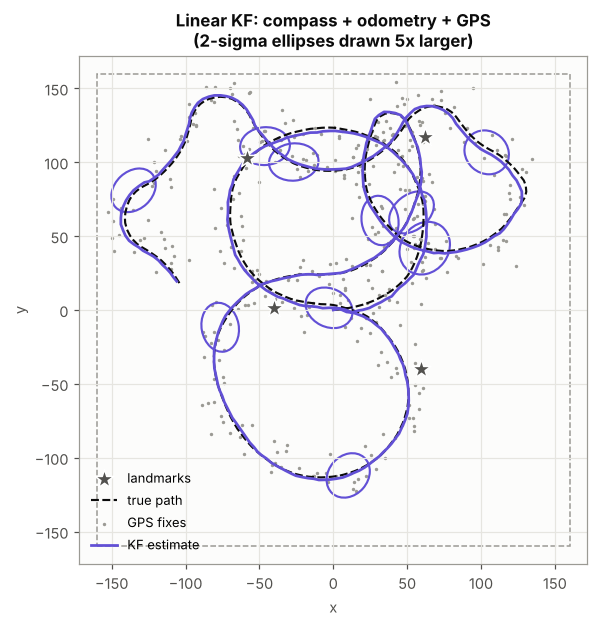

In [3]:
world = World.default()
run = simulate(world, n_steps=400, seed=1)
P0 = np.diag([10.0, 10.0, 0.05])

kf = CompassGpsKF.from_world(world, run.truth[0], P0)
res = run_filter(kf, run)

fig, ax = plt.subplots(figsize=(6, 6))
viz.plot_world(ax, world, label_landmarks=False)
viz.plot_path(ax, run.truth, "truth", label="true path")
ax.scatter(run.z_gps[:, 0], run.z_gps[:, 1], s=5, color=viz.MUTED, lw=0, label="GPS fixes")
viz.plot_path(ax, res.means, "KF", label="KF estimate")
for t in range(20, run.n_steps + 1, 40):
    viz.cov_ellipse(ax, res.means[t], 25 * res.covs[t], n_sigma=2, name="KF")
ax.set_title("Linear KF: compass + odometry + GPS\n(2-sigma ellipses drawn 5x larger)")
ax.legend(loc="lower left", fontsize=8.5)
plt.show()

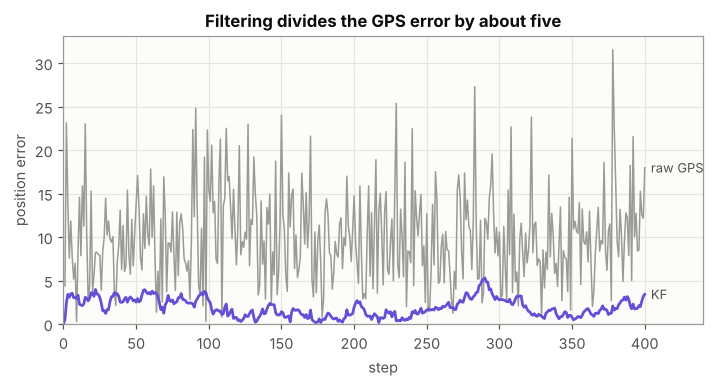

RMS error: raw GPS 11.34,  KF 2.14


In [4]:
e_kf = position_error(res.means, run.truth)
e_gps = np.r_[np.nan, np.hypot(*(run.z_gps - run.truth[1:, :2]).T)]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(e_gps, color=viz.MUTED, lw=1.0)
ax.plot(e_kf, color=viz.COLORS["KF"], lw=1.8)
ax.set_xlabel("step"); ax.set_ylabel("position error"); ax.set_ylim(bottom=0); ax.set_xlim(0, 440)
viz.label_line_end(ax, e_gps, "raw GPS")
viz.label_line_end(ax, e_kf, "KF")
ax.set_title("Filtering divides the GPS error by about five")
plt.show()
print(f"RMS error: raw GPS {np.sqrt(np.nanmean(e_gps**2)):.2f},  KF {np.sqrt(np.mean(e_kf[20:]**2)):.2f}")

## 3. The gain settles

$P$ and $K$ do not depend on the measurements at all, only on $F, H, Q, R$ and $P_0$ (here
also on the heading, through $Q_t$). Starting from the large $P_0$, the filter first trusts
the GPS ($K \approx I$). Then the variance settles where what the motion adds ($Q$) balances
what each fix removes: the steady state of the Riccati recursion
$\bar P \mapsto F(\bar P - \bar P H^\top S^{-1} H \bar P)F^\top + Q$.

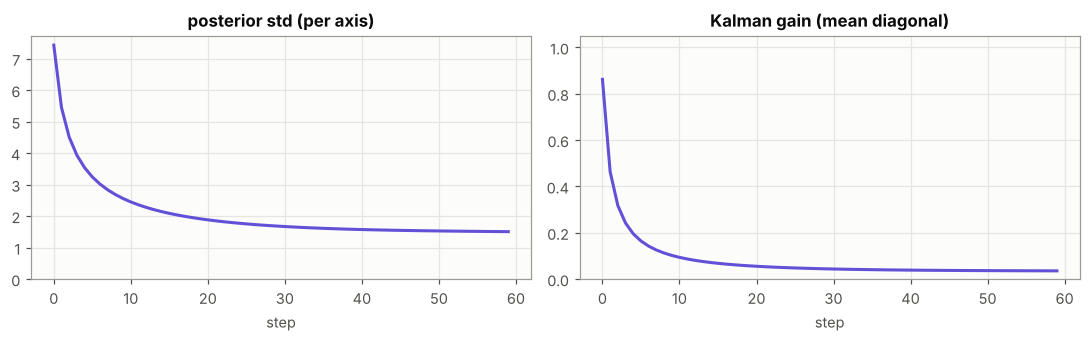

In [5]:
kf2 = CompassGpsKF.from_world(world, run.truth[0], np.diag([400.0, 400.0, 0.05]))
tr, gain = [], []
for t in range(60):
    kf2.predict_from_run(run, t)
    kf2.update_from_run(run, t)
    tr.append(np.sqrt(np.trace(kf2.cov) / 2))
    gain.append(np.trace(kf2.kf.K) / 2)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.2))
a1.plot(tr, color=viz.COLORS["KF"]); a1.set_title("posterior std (per axis)"); a1.set_xlabel("step")
a2.plot(gain, color=viz.COLORS["KF"]); a2.set_title("Kalman gain (mean diagonal)"); a2.set_xlabel("step")
a1.set_ylim(bottom=0); a2.set_ylim(0, 1.05)
plt.tight_layout(); plt.show()

## 4. Is the filter honest? NEES

A small error is not enough: the filter must also *know* how large its error is, because the
covariance is what downstream decisions (and the next update) rely on. For a correct filter
the **normalised estimation error squared**
$$
\epsilon_t = (x_t - \hat x_t)^\top P_t^{-1} (x_t - \hat x_t)
$$
is $\chi^2$-distributed with $n = \dim x$ degrees of freedom, so it averages $n$ ($= 2$
here). Averaged over $N$ independent runs, $N\bar\epsilon_t$ is $\chi^2_{nN}$, which gives an
acceptance band. Above the band the filter is **over-confident** (it claims more precision
than it has), below it is **pessimistic**.

For the test to be fair the initial estimate must itself be a draw from the initial belief:
$\hat x_0 \sim \mathcal N(x_0, P_0)$. Starting exactly at the truth with a large $P_0$ would
make the first steps look pessimistic.

The experiment below runs 50 Monte Carlo runs three times: with the right GPS noise, with a
filter that believes the GPS is 4 times *better* than it is, and with one that believes it
is 4 times *worse*.

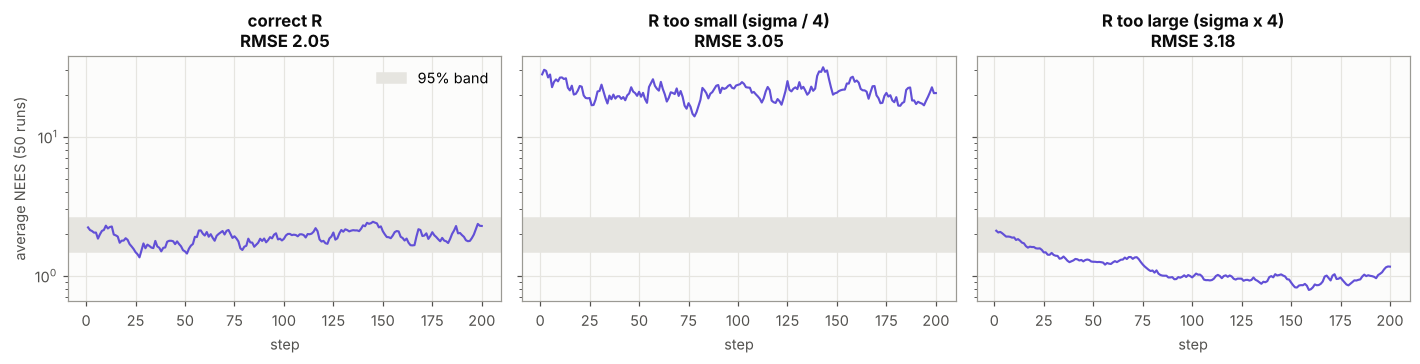

In [6]:
N = 50
runs = [simulate(world, n_steps=200, seed=100 + k) for k in range(N)]
lo, hi = nees_bounds(2, N)
cases = {"correct R": 1.0, "R too small (sigma / 4)": 0.25, "R too large (sigma x 4)": 4.0}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, (label, k) in zip(axes, cases.items()):
    ne, rm = [], []
    for i, r in enumerate(runs):
        x0 = r.truth[0] + np.r_[np.random.default_rng(i).multivariate_normal([0, 0], P0[:2, :2]), 0.0]
        f = CompassGpsKF(x0, P0, world.sigma_step, world.sigma_compass, k * world.sigma_gps)
        rr = run_filter(f, r)
        ne.append(nees(rr.means, rr.covs, r.truth))
        rm.append(position_error(rr.means, r.truth))
    ne = np.mean(ne, axis=0)
    ax.axhspan(lo, hi, color=viz.GRID, label="95% band")
    ax.plot(np.arange(1, len(ne)), ne[1:], color=viz.COLORS["KF"], lw=1.4)
    ax.set_yscale("log"); ax.set_title(f"{label}\nRMSE {np.sqrt(np.mean(np.square(rm)[:, 20:])):.2f}")
    ax.set_xlabel("step")
axes[0].set_ylabel("average NEES (50 runs)"); axes[0].legend(loc="upper right")
plt.tight_layout(); plt.show()

* With the right $R$ the average NEES stays inside the band: the covariance is honest.
* Believing the GPS too much makes the estimate jumpy (higher RMSE) **and** the covariance
  far too small. NEES $\gg 2$: the filter is wrong and certain.
* Believing it too little makes the filter sluggish and pessimistic (NEES $\ll 2$). It also
  leans on dead reckoning more than it should.

NEES needs the truth, so it is a tool for simulation studies like this one. On real data the
same idea is applied to the innovations (NIS: $y^\top S^{-1} y \sim \chi^2_{\dim z}$).

## 5. What we gave up

The compass made the model linear, but it is a crutch. Without it the heading is part of the
state, the motion model contains $\cos\theta$ and $\sin\theta$, and the range–bearing sensor is
non-linear too. The next notebook handles that by **linearising**.